# Estadística

* Materias:
    * Fundamentos de Estadísticas (UNO)
    * Métodos Estadísticos para Inteligencia Artificial (UNAJ)

1. Nociones de probabilidades
2. Estadística descriptiva
3. Test de hipótesis
4. Regresión
5. Estadística no paramétrica

## 1. Nociones de Probabilidades

### Introducción

* **Estadística**: recopilación, organización, análisis y uso de datos para tomar decisiones razonables basadas en tal análisis
* **Población**: totalidad de las observaciones en las cuales se tiene cierto interés
* **Individuo**: cada uno de los elementos de la población
* **Muestra**: subconjunto de observaciones seleccionada de una población
    * **Muestra aleatoria**: muestra cuyos elementos son elegidos al azar
    * **Muestra representativa**: es posible inferir importantes conclusiones sobre la población
* **Variable aleatoria**: función que asigna un valor numérico al resultado de un experimento aleatorio
* **Estadística inductiva**: estudia la muestra infiriendo
* **Estadística descriptiva**: estudia la muestra sin inferir alguna conclusión sobre la población. Métodos para recolectar, organizar y resumir datos

### Inferencia estadística

* Métodos y técnicas que permiten inducir cuál es el comportamiento de una población con un riesgo de error medible en términos de probabilidad
* Métodos paramétricos:
    * **métodos de estimación de parámetros**
    * **métodos de contraste de hipótesis**
* Ambos se basan en el conjunto teórico de la distribución de probabilidad del estadístico muestral que se utiliza como estimador de un parámetro

### Probabilidades y Distribuciones

* Es el estudio de la aleatoriedad. $P(A) = c \mid  0 \leq c \leq 1$
* **Variable Aleatoria (VAs)** $X$: es una función que asocia valores numéricos a los resultados de un experimento aleatorio. Tipos:
    * **VAs discretas**: función de prob puntual (fpp).  $P(X=x_i)$
        * Binomial, Geométrica, Poisson, etc.
    * **VAs continuas**: función de densidad de prob (fdp). $f(X)$
        * Uniforme, Normal, X-cuadrado, etc
* Prob. en un intervalo, se utiliza la función de distribución acumulada (Fda): $P(X \leq x) = F(x)$
* **Esperanza (o valor esperado, o media). E(X)**: dice donde está el centro o valor típico de la distribución
* **Varianza. V(X)**: indica que tan dispersos o alejados están los valores respecto de la media

### Distribuciones de probabilidades discretas

* Distribución que define las probabilidades de una VA discreta
* Sólo puede tomar un número finito de valores
* Se asocia cada valor de la variable discreta que representa $x_i$ a un valor de probabilidad $f(x_i) = p_i$. La suma de todas las prob es igual a 1
    * $f(x_i) \geq 0$
    * $\Sigma^n_{i=1} f(x_i) = 1$
    * $f(x_i) = P(X=x_i)$

| Distribución   | Notación                  | donde ...                                | Ejemplo | Esperanza $E(X)$ | Varianza $V(X)$      |
|----------------|---------------------------|------------------------------------------| --      |------------------|----------------------|
| **Binomial**   | $X \sim Bin(n,p)$         | $n$: total experimentos, $p$: prob exito | número de veces que sale "cara" al lanzar una moneda | $\mu = np$       | $\sigma^2 = np(1-p)$ |
| **Geométrica** | $X \sim Geométrica(p)$    | $p$: prob exito                          | número de autos que pasan por una ruta hasta ver un auto amarillo | $\mu = 1/p$      | $\sigma^2 = (1-p)/p^2$ |
| **Poisson**    | $X \sim Poisson(\lambda)$ | $\lambda$: veces en el intervalo         | número de llamadas que recibe una central telefónica por minuto | $\mu = \lambda$  | $\sigma^2 = \lambda$ |

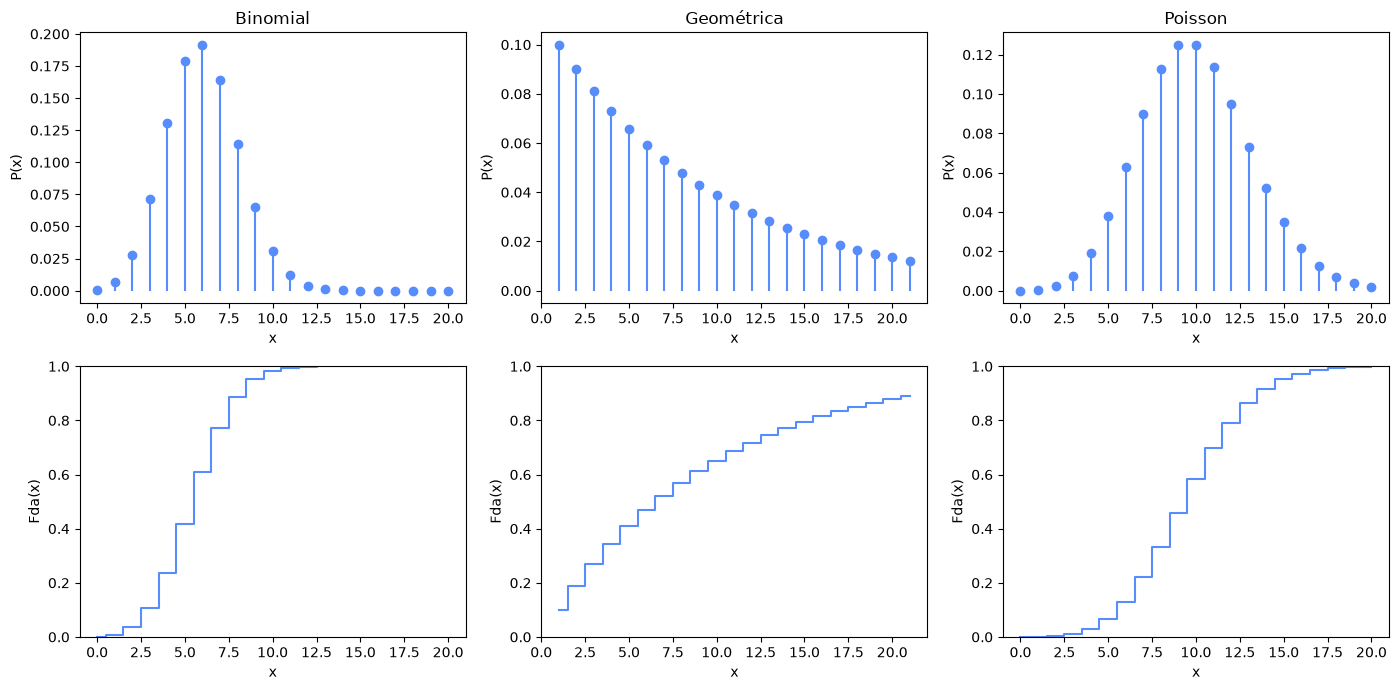

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, geom, poisson

def graficar_distribucion(axs, columna, x, dist, titulo, **params):
    # PMF (Probability Mass Function) = función de probabilidad P(x)
    y_pmf = dist.pmf(x, **params)
    axs[0, columna].stem(x, y_pmf, basefmt=' ')
    axs[0, columna].set_title(titulo)
    axs[0, columna].set_xlabel('x')
    axs[0, columna].set_ylabel('P(x)')

    # CDF (Cumulative Distribution Function) = función de distribución acumulada Fda(x)
    y_cdf = dist.cdf(x, **params)
    axs[1, columna].step(x, y_cdf, where='mid')
    axs[1, columna].set_xlabel('x')
    axs[1, columna].set_ylabel('Fda(x)')
    axs[1, columna].set_ylim(0, 1)

# Secuencia de números enteros
x = np.arange(0, 21)

# Crear figura con 2 filas y 3 columnas
fig, axs = plt.subplots(2, 3, figsize=(14, 7))

graficar_distribucion(axs, 0, x, binom, 'Binomial', n=20, p=0.3)
graficar_distribucion(axs, 2, x, poisson, 'Poisson', mu=10)
graficar_distribucion(axs, 1, x + 1, geom, 'Geométrica', p=0.1)

plt.tight_layout()
plt.show()

* **Binomial**: la mayor probabilidad estará alrededor de 6
* **Geométrica**: decrece rápidamente; los valores pequeños son más probables
* **Poisson**: se concentra alrededor de $\lambda = 10$

### Distribuciones de probabilidades continuas

* Distribución que define las probabilidades de una VA continua
* Puede tomar infinitos valores dentro de un intervalo
* A cada valor se le asocia una función de densidad de probabilidad $f(x)$ que no representa directamente la probabilidad de un punto, sino la densidad en torno a ese valor.
    * $f(x) \geq 0$
    * $\int^{+\infty}_{-\infty} f(x)dx = 1$
    * $P(a \leq X \leq b) = \int^b_a f(x)dx$

| Distribución                  | Notación               | donde ...                                | Ejemplo | Esperanza $E(X)$ | Varianza $V(X)$           |
|-------------------------------|------------------------|------------------------------------------| --      |------------------|---------------------------|
| **Uniforme**                  | $X \sim U(a,b)$        | $a$,$b$ definen el intervalo de reciprocidad | si un experimento puede dar cualquier valor entre 5 y 9 con igual probabilidad | $\mu = (a+b)/2$  | $\sigma^2 = (b-a)^2 / 12$ |
| **Normal**                    | $X \sim N(\mu,\sigma)$ | $\mu$: media, $\sigma$: desviación estándar | forma de campana centrada en la media. Ej. estatura de alumnos de un curso | $E(X) = \mu$     | $V(X) = \sigma^2$         |
| **Normal Estándar**           | $X \sim N(0,1)$        |||                  |
| **Chi-cuadrado o de Pearson** | $X \sim \chi^2_k$      | $k$: grados de libertad | es la suma del cuadrado de k variables aleatorias independientes con distribución normal | $E(X) = k$       | $V(X) = 2k$               |
| **t de Student**              | $X \sim t_v$           | $v = n-1$ | para estimar la media de una población normal cuando el tamaño muestral es pequeño y la desviación es desconocida | $E(X) = 0$       | $V(X) = v/(v-2); v > 2$   |

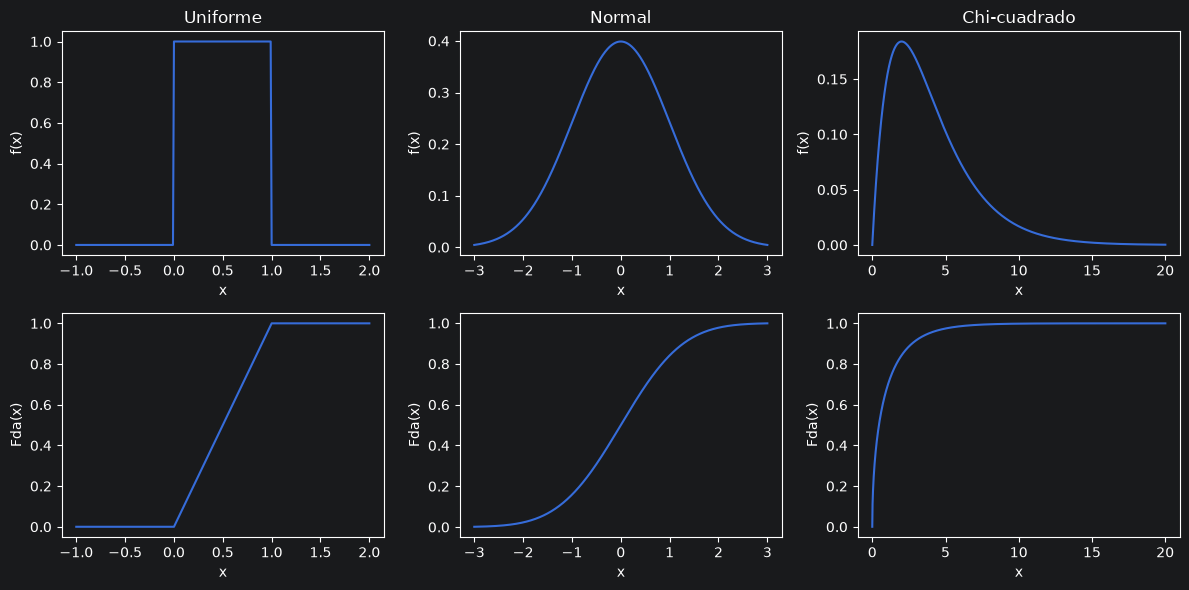

In [6]:
import matplotlib.pyplot as plt
from scipy.stats import uniform, norm, chi2

def graficar_distribucion(axs, col, x, dist, titulo, pdf_params=None, cdf_params=None):
    pdf_params = pdf_params or {}
    cdf_params = cdf_params or {}

    # Densidad
    axs[0, col].plot(x, dist.pdf(x, **pdf_params))
    axs[0, col].set_title(titulo)
    axs[0, col].set_xlabel('x')
    axs[0, col].set_ylabel('f(x)')

    # Acumulada
    axs[1, col].plot(x, dist.cdf(x, **cdf_params))
    axs[1, col].set_xlabel('x')
    axs[1, col].set_ylabel('Fda(x)')

# Crear figura con 2 filas y 3 columnas de subplots
fig, axs = plt.subplots(2, 3, figsize=(12, 6))

graficar_distribucion(
    axs, 0,
    np.arange(-1, 2.01, 0.01),  # Genera secuencia de números reales
    uniform,
    'Uniforme',
    pdf_params={'loc': 0, 'scale': 1},
    cdf_params={'loc': 0, 'scale': 1}
)

graficar_distribucion(
    axs, 1,
    np.arange(-3, 3.01, 0.01), # Secuencia de valores entre -3 y 3
    norm,
    'Normal'                   # normal estándar (mu=0, sigma=1)
)

graficar_distribucion(
    axs, 2,
    np.arange(0, 20.01, 0.01),  # Secuencia de valores entre 0 y 20
    chi2,
    'Chi-cuadrado',
    pdf_params={'df': 4},       # con 4 grados de libertad
    cdf_params={'df': 1}        # con 1 grado de libertad
)

plt.tight_layout()
plt.show()

### Cuantiles

* **Cuantil**: es un punto que divide al conjunto de datos en dos subconjuntos:
    * uno con valores menores o iguales que él
    * otro con valores mayores que él

In [7]:
# Calculo el cuantil x_{0.25}
c = 0.25
xc = norm.ppf(c)  # Cálculo del cuantil (inverso de la cdf)

# Probabilidad acumulada a la izquierda de xc
z = norm.cdf(xc)  # Equivalente a pnorm(xc) en R

print(f'Cuantil x_{0.25}: {xc}')
print(f'Probabilidad acumulada a la izquierda: {z}')

Cuantil x_0.25: -0.6744897501960817
Probabilidad acumulada a la izquierda: 0.25


### Números aleatorios

* Generar números pseudo-aleatorios con distribución Normal con media $\mu = 0$ y desviación típica $\sigma = 1$

In [9]:
import numpy as np

# Setea la semilla
np.random.seed(182)

# Genera 5 números aleatorios N(0,1)
y = np.random.normal(loc=0, scale=1, size=5)
print(f'Números aleatorios N(0,1): {y}')

Números aleatorios N(0,1): [ 0.26416281 -0.34912185 -0.11645481  1.05844668  1.22340598]


* Generar números pseudo-aleatorios con distribución Chi cuadrado con 4 grados de libertad

In [10]:
from scipy.stats import chi2

# Parámetros
n = 10000
k = 4 # Grados de libertad

y = chi2.rvs(df=k, size=n)

## 2. Estadística descriptiva

* Es un conjunto de técnicas numéricas y gráficas para obtener, organizar, presentar y describir un conjunto de datos con el propósito de facilitar el uso, extraer conclusiones (inferencias) sobre la población a la que pertenecen
* Ejemplos:
    * construcción de tablas de frecuencias
    * descripción numérica
    * descripción gráfica
* **Variable estadística**: característica de la muestra bajo estudio

| Tipos                          | Clases    | Ejemplo                                |
|--------------------------------|-----------|----------------------------------------|
| **cualitativas o categóricas** | Nominal   | sexo, razo, color_ojos, ...            |
|                                | Ordinal   | grado_contaminacion, calificacion, ... |
| **cuantitativas**              | discretas | nro_hermanos, num_materias, ...        |
|                                | continuas | peso, altura, ...                      |

* **Datos**: valores que se obtienen para cada variable
* **Observaciones**: conjunto de las mediciones obtenidas para una determinada muestra


### Tablas de frecuencias

* Se organizan los datos en categorías o grupos de valores que describen una característica de los individuos bajo estudio
* **Frecuencia absoluta**: es el número de observaciones que caen dentro de cada intervalo
* **Frecuencia absoluta acumulada**: es la suma de las frecuencias absolutas de una clase o grupo de la muestra con la anterior
* **Frecuencia relativa**: es el número de veces que se repite un número en un conjunto de datos respecto al total
* **Frecuencia relativa acumulada**: es el cociente entre la frecuencia absoluta acumulada de un terminado valor y el número total de datos

| $X_i$     | F absoluta $(n_i)$ | F absoluta acumulada $(N_i)$ | F relativa $(f_i = n_i/N)$ | F relatica acumulada $(F_i=N_i/N)$ |
|-----------|--------------------|------------------------------|----------------------------|------------------------------------|
| **1**     | 7                  | 7                            | 0.06                       | 0.06                               |
| **2**     | 19                 | 26                           | 0.15                       | 0.21                               |
| **3**     | 25                 | 51                           | 0.20                       | 0.41                               |
| **4**     | 12                 | 63                           | 0.10                       | 0.50                               |
| **5**     | 23                 | 86                           | 0.18                       | 0.69                               |
| **6**     | 15                 | 101                          | 0.12                       | 0.81                               |
| **7**     | 8                  | 109                          | 0.06                       | 0.87                               |
| **8**     | 16                 | 125                          | 0.13                       | 1.00                               |
| **Total** | **125**            | **125**                      | **1**                      | **1**                              |

### Descripción numérica

* Medidas numéricas describen las características de los datos
* Tipos: posición o localización (alrededor de qué valores se encuentran los datos) y dispersión (cuánto se dispersan)

| Medidas de posición | Tendencia  |             |                                                                                                 |
|---------------------|------------|-------------|-------------------------------------------------------------------------------------------------|
| **media**           | central    | $\bar{x}$   | valor promedio de la muestra                                                                    |
| **mediana**         | central    | $\tilde{x}$ | valor hasta el cual se encuentran el 50% de los casos  (datos ordenados)                        |
| **moda**            | central    |             | observación que más se repite en la muestra. Puede existir más de una moda                      |
| **cuartiles**       | no central | $Q$         | $Q_1$ (25%), $Q_2$ (50%) y $Q_3$ (75%) dividen la muestra en 4 partes iguales (datos ordenados) |
| **percentiles**     | no central | $p$         | $p_{0.25}=Q_1, p_{0.5}=Q_2, p_{0.75}=Q_3$ dividen la muestra en 100 partes iguales              |

In [12]:
import numpy as np
from collections import Counter

y = [100, 200, 200, 250, 600]
print(f'Media: {np.mean(y)}')
print(f'Mediana: {np.median(y)}')
print(f'Moda: {Counter(y).most_common(1)[0][0]}')
print(f'Quartiles: {np.quantile(y, [0, 0.25, 0.5, 0.75, 1])}')
print(f'Percentiles: {np.percentile(y, [25, 50, 75])}')

Media: 270.0
Mediana: 200.0
Moda: 200
Quartiles: [100. 200. 200. 250. 600.]
Percentiles: [200. 200. 250.]


| Medidas de dispersión            | tipo     |                                                          |                                                                                                 |
|----------------------------------|----------|----------------------------------------------------------|-------------------------------------------------------------------------------------------------|
| **rango de la muestra**          | absoluta | $R = max\{x_i\} - min\{x_i\}$                            | diferencia entre las observaciones más grande y más pequeña                                     |
| **rango intercuartílico**        | absoluta | $RIC = Q_3 - Q_1$                                        | diferencia entre el quartil superior e inferior                                                 |
| **varianza muestral**            | absoluta | $s^2 = \frac{1}{n} \Sigma^n_{i=1}(x_i - \bar{x})^2$      |                                                                                                 |
| **desviación estándar muestral** | absoluta | $s = \sqrt{\frac{1}{n} \Sigma^n_{i=1}(x_i - \bar{x})^2}$ |                                                                                                 |
| **coeficiente de variación**     | relativa | $CV = \frac{s}{\bar{x}}$                                 | comparan 2 ó + muestras que difieren de manera considerable en la magnitud de las observaciones |

In [15]:
y = [100, 200, 200, 250, 600]
print(f'Rango: {np.max(y) - np.min(y)}')
print(f'Rango intercuartílico: {np.quantile(y, 0.75) - np.quantile(y, 0.25)}')
print(f'Varianza muestral: {np.var(y)}')
print(f'Desviación estándar muestral: {np.std(y)}')
print(f'coeficiente de variación: {np.std(y) / np.mean(y)}')

Rango: 500
Rango intercuartílico: 50.0
Varianza muestral: 29600.0
Desviación estándar muestral: 172.04650534085255
coeficiente de variación: 0.6372092790401946


In [20]:
import pandas as pd

pd.Series(y).describe()

count      5.000000
mean     270.000000
std      192.353841
min      100.000000
25%      200.000000
50%      200.000000
75%      250.000000
max      600.000000
dtype: float64

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets

iris = datasets.load_iris()
iris_df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
iris_df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [23]:
iris_df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### Descripción gráfica

* Histograma
* Distribución acumulada empírica
* QQplots
* Diagrama de cajas

### Histogramas

* Representación de la distribución de los datos
* Permite visualizar dónde están los datos y tener una idea de su distribución
* Base de cada rectángulo: intervalo de la clase
* Altura: número de frecuencia

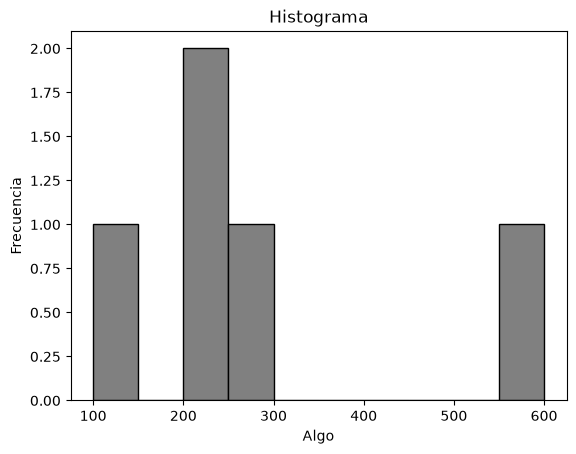

In [29]:
y = [100, 200, 200, 250, 600]
plt.hist(y, bins=10, color='gray', edgecolor='black')
plt.title('Histograma')
plt.xlabel('Algo')
plt.ylabel('Frecuencia')
plt.show()

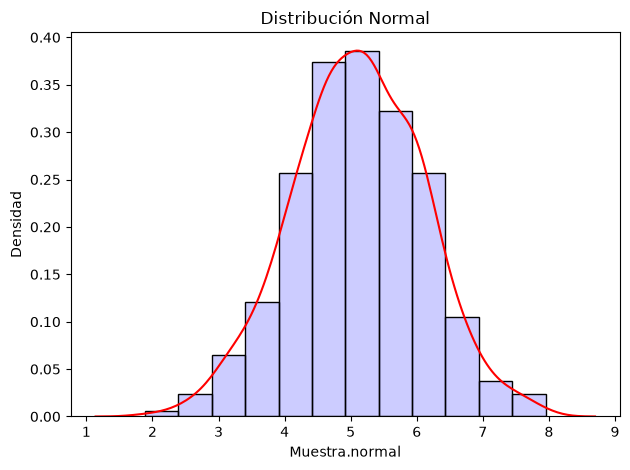

In [33]:
n = 1000
normal = np.random.normal(loc=5, scale=1, size=n) # N(5,1)
sns.histplot(normal,
             binwidth=0.5,
             kde=False,
             stat='density', # el histograma se normaliza de modo que el área bajo las barras sea = 1
             color='blue',
             edgecolor='black',
             alpha=0.2)
sns.kdeplot(normal, color='red') # polígono de frecuencia suavizado
plt.xlabel('Muestra.normal')
plt.ylabel('Densidad')
plt.title('Distribución Normal')
plt.tight_layout()
plt.show()

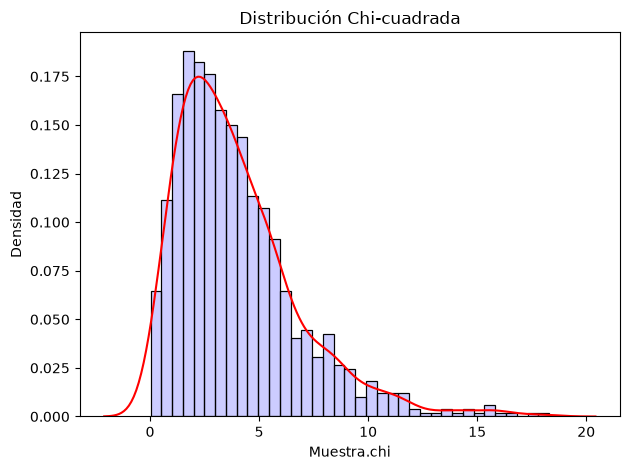

In [34]:
chi = np.random.chisquare(df=4, size=n)
sns.histplot(chi,
             binwidth=0.5,
             kde=False,
             stat='density',
             color='blue',
             edgecolor='black',
             alpha=0.2)
sns.kdeplot(chi, color='red')
plt.xlabel('Muestra.chi')
plt.ylabel('Densidad')
plt.title('Distribución Chi-cuadrada')
plt.tight_layout()
plt.show()

In [35]:
pd.DataFrame({'N': normal, 'X': chi}).describe()

,N,X
count,1000.000000,1000.000000
mean,5.105447,3.975941
std,0.990995,2.819622
min,1.886195,0.021163
25%,4.445177,1.947209
50%,5.114037,3.393044
75%,5.810006,5.321806
max,7.951063,18.297736


### Gráfico Q-Q (QQplots)

* Útil para probar normalidad de una muestra (es decir, verificar si tiene distribución normal)
* Si la distribución es normal, los datos se concentrarían en una recta:

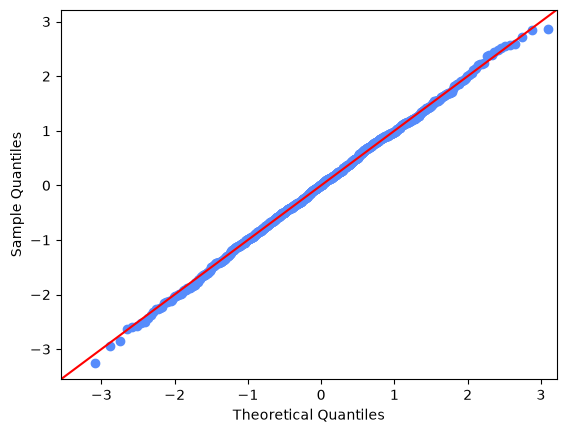

In [40]:
import statsmodels.api as sm

sm.qqplot(normal, fit = True, line='45')
plt.show()

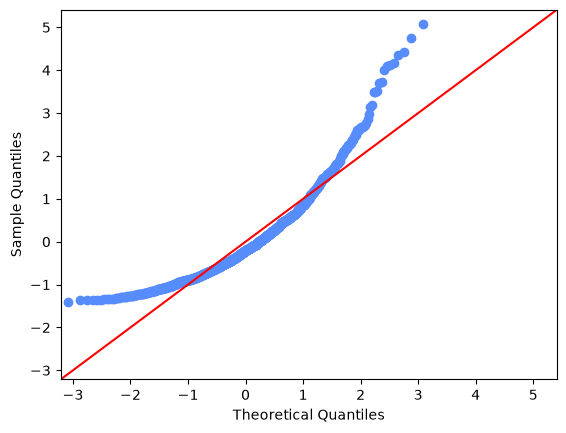

In [41]:
sm.qqplot(chi, fit = True, line='45')
plt.show()

### Diagramas de caja

* Se usa para determinar outliers, fuera del intervalo (LI;LS)
* Se construye a partir de las siguientes medidas:
    * Q1 y Q3 delimitan la caja central
    * RIC es la longitud de la caja
    * Q2 (mediana) es la línea horizontal en la caja central
    * Los límites inferior y superior (bigotes) se calculan como:

$$LI = max\{min\{x_i\}, Q_1 - 1.5*RIC\}$$
$$LS = min\{max\{x_i\}, Q_3 + 1.5*RIC\}$$

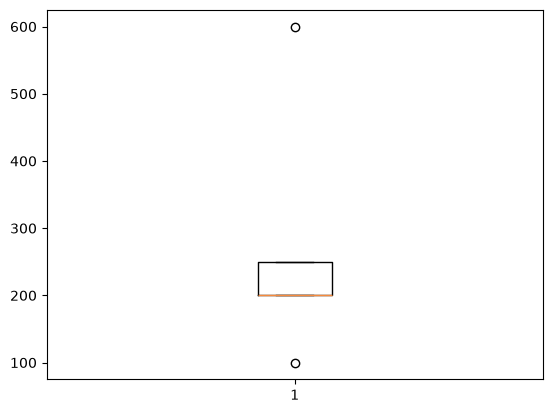

In [43]:
y = [100, 200, 200, 250, 600]

plt.boxplot(y)
plt.show()

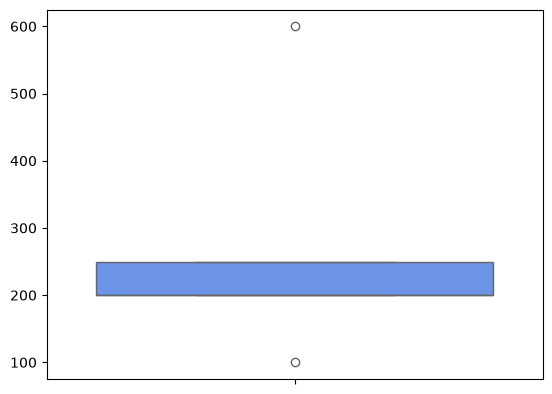

In [45]:
sns.boxplot(data=y)
plt.show()

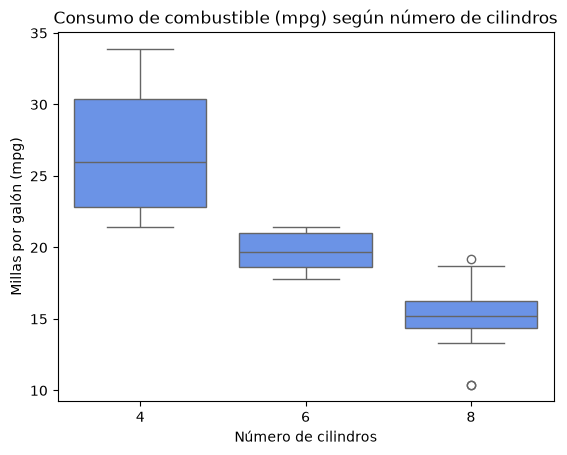

In [46]:
mtcars = sm.datasets.get_rdataset('mtcars', 'datasets').data
sns.boxplot(x='cyl', y='mpg', data=mtcars)
plt.title('Consumo de combustible (mpg) según número de cilindros')
plt.xlabel('Número de cilindros')
plt.ylabel('Millas por galón (mpg)')
plt.show()


* A medida que aumenta la cilindrada los datos están menos dispersos
* A mayor cilindrada menor consumo
* Para 8 cilindros aparecen los valores extremos o atípicos

## Introducción a Test de Hipótesis

### Inferencia estadística

1. Formular hipótesis
2. Diseñar experimento: para confirmar o rechazar una hipótesis. Ej. prueba A/B
3. Recolectar datos
4. Inferir / conclusiones

### 1. Formular la Hipótesis

* Es una suposición inicial
* Afirmación sobre la población
* Ejemplo de hipótesis ($H_0$ **hipótesis nula**):
    * **Proporción 50:50 entre chicles rojos y azules**

### 2. Muestreo

* Simulamos la extracción de 10 chicles, varias veces (30) y anotamos cúantos rojos sacamos en c/u

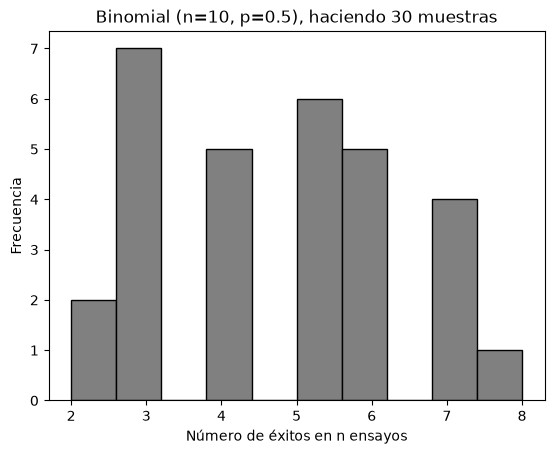

In [50]:
n = 10
p = 0.5
muestras = 30
datos = np.random.binomial(n, p, muestras)

plt.hist(datos, bins=10, color='gray', edgecolor='black')
plt.title(f'Binomial (n={n}, p={p}), haciendo {muestras} muestras')
plt.xlabel('Número de éxitos en n ensayos')
plt.ylabel('Frecuencia')
plt.show()

* Los resultados varían (**variabilidad natural**)
* **Los resultados se agrupan alrededor del valor esperado**
* Eventos raros (eventos muy poco probables su la hipótesis es cierta)
* Zona de sospecha: región de resultados inusuales, si caemos allí, dudamos de la hipótesis inicial

### 3. Emitir un veredicto

1. Reafirmar la hipótesis (50:50)
2. Define la zona de sospecha
3. Obtené la muestra real
4. Compará con la zona
5. Decidí: aceptar o rechazar hipótesis

* Resultado: 9 rojos de 10
* Evento raro bajo 50:50
* Conclusión: **rechazar hipótesis nula**

>Nuestro resultado (9 rojos) cae directamente dentro de nuestra "zona de sospecha". Es tan improbable que obtengamos 9 rojos por pura casualidad si nuestra hipótesis de 50:50 fuera cierta, que tenemos una fuerte evidencia en su contra. Concluimos que la proporción real de chicles rojos no es 50:50

* En cambio, con 6 rojos: no hay evidencia suficiente para rechazar

**La prueba de hipótesis estadística** se inventó para proteger al analista de ser engañado por el azar y tomar conclusiones incorrectas.
* Una lógica para **decidir** bajo incertidumbre
* Herramienta de razonamiento crítico

### Zonas de aceptación y rechazo

* "Ubicación" de la observación de la muestra $X_{obs}$
* definir región de rechazo con alguna **significancia** ($\alpha$)

$$P\{X_{obs} < x_{\alpha/2} o X_{obs} > x_{1-\alpha/2} \mid H_0 \text{verdadera}\}$$

* **Decisión fuerte**: se le da muchas chances de salir a la observación en la región de aceptación (1-$\alpha$, es decir, 95% de probabilidad)
* **Decisión débil**: si tomamos una muestra y sacamos 6 chicles rojos entonces... no hay evidencia para rechazar

>No estamos "probando" que la hipótesis de 50:50 sea cierta. Se está diciendo que la evidencia que hemos recogido no es lo suficientemente fuerte como para descartarla

### Errores

|                         | $H_0$ es Verdadera                         | $H_A$ es Verdadera                                |
|-------------------------|--------------------------------------------|---------------------------------------------------|
| Rechazar $H_0$          | **Error Tipo I**. Falso Positivo. $\alpha$ | OK. Verdadero Positivo. $\pi = 1 - \beta$ (power) |
| Fallo al rechazar $H_0$ | Correcto. Verdadero Negativo. $1 - \alpha$ | **Error Tipo II**. Falso Negativo. $\beta$        |

* **power (potencia de un test)**: es la probabilidad de que el test rechace correctamente la hipótesis nula

### Error Tipo I

Probabilidad de equivocarme al rechazar la hipótesis nula cuando ésta es verdadera

$$\alpha = P\{X_{obs} < x_{\alpha/2} o X_{obs} > x_{1-\alpha/2} \mid H_0 \text{ verdadera}\}$$

In [53]:
from scipy.stats import binom

n = 10       # número de ensayos
p = 0.5      # probabilidad de éxito
alfa = 0.05  # cuantil deseado
x_alfa_2 = binom.ppf(alfa/2, n, p)
x_1_alfa_2 = binom.ppf(1-alfa/2, n, p)
print(f'región de aceptación ({x_alfa_2},{x_1_alfa_2})')

región de aceptación (2.0,8.0)


### Error Tipo II

Probabilidad de equivocarme al aceptar la hipótesis nula cuando ésta **NO** es verdadera

$$\beta = P\{x_{\alpha/2} \leq X_{obs} \leq x_{1-\alpha/2} \mid H_0 \text{ falsa}\}$$

In [2]:
from scipy.stats import binom

n = 10
p1 = 0.9
beta = binom.cdf(8, n, p1)-binom.cdf(1, n, p1)  # P(2<= x <= 8)
print('Error de tipo II, β: ',beta)
print('Potencia del test, π(β): ',1-beta)

Error de tipo II, β:  0.26390106179999995
Potencia del test, π(β):  0.7360989382


### p-valor

* Cuantifica la cercanía del valor observado a la región de aceptación
* Mientras más pequeño sea, mas lejos de la región de aceptación
* Es el nivel de significancia más pequeño que conduce al rechazo de la hipótesis nula $H_0$
* Si p_valor > $\alpha$ entonces no hay evidencia para rechazar $H_0$

In [3]:
# p-valor < alfa entonces rechazo H0
p = 0.5
p_valor_2 = 1 - binom.cdf(8, n, p) #P(X>=9)
print('p-valor/2: ', p_valor_2)

p_valor_2 = 1 - binom.cdf(5, n, p) #P(X>=6)
print('p-valor/2: ', p_valor_2)

p-valor/2:  0.0107421875
p-valor/2:  0.376953125


### Otro ejemplo: tensión hogareña

* $H_0 : \mu = \mu_0 = 220V$
* $H_1 : \mu \ne \mu_0 = 220V$
* $\bar{x} = 230.3V$
* $n = 25 \text{ mediciones}$
* $\sigma = 20V$

* El propósito del test es establecer si la evidencia experimental soporta el rechazo de $H_0$
* La decisión se basa en la "ubicación" de la observación de la muestra ($\bar{x}$). Por ejemplo: en la figura se muestra una observación que cae fuera de la región de aceptación. Por lo tanto se **rechaza la hipótesis nula**

* **Error de Tipo I**
* Estadístico $Z_0$:

$$Z_0 = \frac{\bar{X} - \mu_0}{\sigma / \sqrt{n}}$$

$$\alpha = P\{\mid Z_0 \mid > z_{\alpha/2} \mid H_0 \text{ verdadera} \}$$

* El valor observado de mi estadístico de prueba ($z_0$) cae fuera del intervalo $-z_{\alpha/2} \leq Z_0 \leq z_{\alpha/2}$ tendré evidencia como para rechazar la hipótesis nula
* Si elegimos $\alpha = 0.05$, rechazar $H_0$ si $z_0$ > 1.96 o si $z_0$ < -1.96

In [4]:
import scipy.stats as stats

# cálculo de cuantiles para test de hipótesis
alfa = 0.05
zalfa_2_neg = stats.norm.ppf(alfa / 2)      #cuantil x_{0,025}
zalfa_2_pos = stats.norm.ppf(1 - alfa / 2)  #cuantil x_{0,975}
print('Z_α/2: ', zalfa_2_neg)
print('Z_1-α/2: ', zalfa_2_pos)

Z_α/2:  -1.9599639845400545
Z_1-α/2:  1.959963984540054


In [8]:
import math

z0 = (230.3 - 220) / (20 / math.sqrt(25))
z0

2.575000000000003

Como $z_0 > 1.96$ entonces tenemos evidencia suficiente como para **rechazar** $H_0$ con una significancia de 0.05

* **Error de Tipo II**

In [11]:
import numpy as np
import scipy.stats as stats

beta = 0.1
zbeta_neg = stats.norm.ppf(beta)
print(f'Z_β: {zbeta_neg}')

# Ejemplo
sigma = 20 / np.sqrt(30)
mu0 = 220   # esperanza de H0
mu1 = 232.0 # esperanza de H1
alpha = 0.05  # probabilidad error tipo I

# Valores críticos
crit = stats.norm.ppf(1 - alpha / 2, loc=mu0, scale=sigma)
crit_neg = stats.norm.ppf(alpha / 2, loc=mu0, scale=sigma)

# Probabilidad de error de tipo II
beta_value = stats.norm.cdf(crit, loc=mu1, scale=sigma) - stats.norm.cdf(crit_neg, loc=mu1, scale=sigma)
print(f'Probabilidad de error de tipo II (β): {beta_value}')

Z_β: -1.2815515655446004
Probabilidad de error de tipo II (β): 0.09235828257727197


In [12]:
# Potencia del test PI(beta)
power = 1 - beta_value
print(f'Potencia del test, π(β): {power}')

Potencia del test, π(β): 0.907641717422728


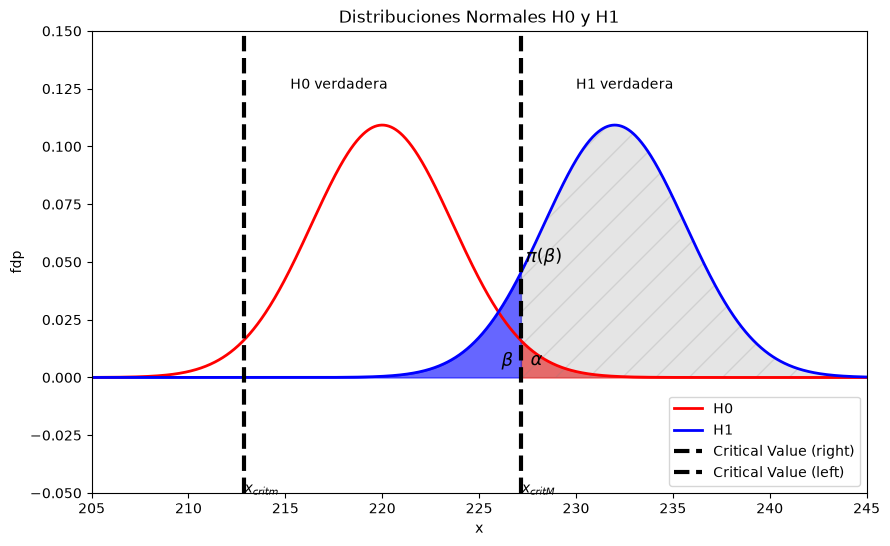

Valor crítico mayor (xcritM): 227.15677657486862
Valor crítico menor (xcritm): 212.84322342513136


In [13]:
import matplotlib.pyplot as plt

# Figura
xLims = [205, 245]
left = np.linspace(xLims[0], crit, 100)
right = np.linspace(crit, xLims[1], 100)
yH0r = stats.norm.pdf(right, mu0, sigma)
yH1l = stats.norm.pdf(left, mu1, sigma)
yH1r = stats.norm.pdf(right, mu1, sigma)

plt.figure(figsize=(10, 6))
x = np.linspace(xLims[0], xLims[1], 1000)
yH0 = stats.norm.pdf(x, mu0, sigma)
yH1 = stats.norm.pdf(x, mu1, sigma)

plt.plot(x, yH0, label='H0', color='red', lw=2)
plt.plot(x, yH1, label='H1', color='blue', lw=2)

plt.fill_between(right, 0, yH0r, color='red', alpha=0.6)
plt.fill_between(left, 0, yH1l, color='blue', alpha=0.6)
plt.fill_between(right, 0, yH1r, color='gray', alpha=0.2, hatch='/')

plt.axvline(x=crit, color='black', linestyle='--', lw=3, label='Critical Value (right)')
plt.axvline(x=crit_neg, color='black', linestyle='--', lw=3, label='Critical Value (left)')

plt.xlim(xLims)
plt.ylim(-0.05, 0.15)
plt.xlabel('x')
plt.ylabel('fdp')
plt.title('Distribuciones Normales H0 y H1')

plt.text(mu0 + 0.3, 0.125, 'H0 verdadera', horizontalalignment='right')
plt.text(mu1 - 2, 0.125, 'H1 verdadera', horizontalalignment='left')
plt.text(crit + 0.25, 0.05, r'$\pi(\beta)$', fontsize=13)
plt.text(crit - 1, 0.005, r'$\beta$', fontsize=13)
plt.text(crit + 0.5, 0.005, r'$\alpha$', fontsize=13)
plt.text(crit + 0.05, -0.05, r'$x_{critM}$', fontsize=10)
plt.text(crit_neg + 0.05, -0.05, r'$x_{critm}$', fontsize=10)

plt.legend()
plt.show()

print('Valor crítico mayor (xcritM):', crit)
print('Valor crítico menor (xcritm):', crit_neg)

* **p_valor**

In [14]:
x_media_observada = (229.6 - mu0) / sigma  # Estandarizo
p_valor = 2 * (1 - stats.norm.cdf(x_media_observada, 0, 1))
print(f'media observada: {x_media_observada}')
print(f'p-valor: {p_valor}')

media observada: 2.6290682760247956
p-valor: 0.008561916896063781


* Como p-valor = 0.0086 <  $\alpha$ = 0.05, entonces se rechaza $H_0$

In [15]:
#Jugando con n y el p-valor:

# Ejemplo: significancia práctica
mu0 = 220.0
mu1 = 229.6
alpha = 0.05

# Defino una función para calcular p-value y potencia
def calculate_p_value_and_power(n, mu0, mu1, alpha):
    sigma = 20 / np.sqrt(n)
    x_media_observada = (229.6 - mu0) / sigma  # Estandarizo
    p_valor = 2 * (1 - stats.norm.cdf(x_media_observada, 0, 1))
    crit = stats.norm.ppf(1 - alpha / 2, loc=mu0, scale=sigma)
    crit_neg = stats.norm.ppf(alpha / 2, loc=mu0, scale=sigma)
    beta = stats.norm.cdf(crit, loc=mu1, scale=sigma) - stats.norm.cdf(crit_neg, loc=mu1, scale=sigma)
    pow = 1 - beta  # Potencia del test PI(beta)
    print(f'n: {n} ----> p-valor: {p_valor} -----> Potencia: {pow}')

# Tamaños de muestra
sample_sizes = [10, 20, 30, 100]

# Calcular el p-valor para cada uno
for n in sample_sizes:
    calculate_p_value_and_power(n, mu0, mu1, alpha)

n: 10 ----> p-valor: 0.12904130509946832 -----> Potencia: 0.3294717397269967
n: 20 ----> p-valor: 0.03182312738649018 -----> Potencia: 0.5740569665465731
n: 30 ----> p-valor: 0.008561916896063781 -----> Potencia: 0.7482877502182744
n: 100 ----> p-valor: 1.586656303897982e-06 -----> Potencia: 0.9977445779714299
